# Assignment 04: Population of Ireland by Sex

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from  matplotlib.patches import Patch

In [2]:
# Load census data from CSO website
url = "https://ws.cso.ie/public/api.restful/PxStat.Data.Cube_API.ReadDataset/FY006A/CSV/1.0/en"
df = pd.read_csv(url)
df.tail(3)

,STATISTIC,Statistic Label,TLIST(A1),CensusYear,C02199V02655,Sex,C02076V03371,Single Year of Age,C03789V04537,Administrative Counties,UNIT,VALUE
9789,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-149d-13a3-e055-000000000001,Cavan County Council,Number,12
9790,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-14a4-13a3-e055-000000000001,Donegal County Council,Number,31
9791,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-1495-13a3-e055-000000000001,Monaghan County Council,Number,7


## Prepare the data

In [3]:
# Remove the "Both sexes" rows (male + female combined), leaving Male and Female
df = df[df["Sex"] != "Both sexes"]
df["Sex"].unique()

array(['Male', 'Female'], dtype=object)

In [4]:
# Remove columns that are not needed
drop_col_list = ['STATISTIC', 'Statistic Label', 'TLIST(A1)', 'CensusYear',
                 'C02199V02655', 'C02076V03371', 'C03789V04537', 'UNIT']
df.drop(columns=drop_col_list, inplace=True)

# Removes the "All ages" total rows
df = df[df["Single Year of Age"] != "All ages"]

# Convert age text such as "5 years" into the number 5, "Under 1 year" becomes 0 and "100 year and over" becomes 100
df['Single Year of Age'] = df['Single Year of Age'].str.replace('Under 1 year', '0')
df['Single Year of Age'] = df['Single Year of Age'].str.replace(r'\D', '', regex=True)

# Convert age and population columns to whole numbers
df['Single Year of Age'] = df['Single Year of Age'].astype('int64')
df['VALUE'] = df['VALUE'].astype('int64')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6464 entries, 3296 to 9791
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Sex                      6464 non-null   object
 1   Single Year of Age       6464 non-null   int64 
 2   Administrative Counties  6464 non-null   object
 3   VALUE                    6464 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 252.5+ KB


In [5]:
# Remove the "Ireland" row which is the national total of all the counties., Keeping it would double the totals and make it the biggest area.
df = df[df["Administrative Counties"] != "Ireland"]
df["Administrative Counties"].unique()

array(['Carlow County Council', 'Dublin City Council',
       'Dún Laoghaire Rathdown County Council', 'Fingal County Council',
       'South Dublin County Council', 'Kildare County Council',
       'Kilkenny County Council', 'Laois County Council',
       'Longford County Council', 'Louth County Council',
       'Meath County Council', 'Offaly County Council',
       'Westmeath County Council', 'Wexford County Council',
       'Wicklow County Council', 'Clare County Council',
       'Cork City Council', 'Cork County Council', 'Kerry County Council',
       'Limerick City & County Council', 'Tipperary County Council',
       'Waterford City & County Council', 'Galway City Council',
       'Galway County Council', 'Leitrim County Council',
       'Mayo  County Council', 'Roscommon County Council',
       'Sligo County Council', 'Cavan County Council',
       'Donegal County Council', 'Monaghan County Council'], dtype=object)

## Part 1: Differences between the sexes by age (all of Ireland)

In [6]:
# Population for each age (rows) and sex (columns), with all the counties added together
df_anal = pd.pivot_table(df, 'VALUE', "Single Year of Age", "Sex", aggfunc="sum")
df_anal.head()

Sex,Female,Male
Single Year of Age,,
0,28186,29610
1,27545,28875
2,28974,30236
3,29483,31001
4,29819,31686


In [7]:
# The total population is 5.1 million
print("Total population:", df_anal[["Male", "Female"]].sum().sum())

Total population: 5149139


### Weighted mean age
Weighted mean age = sum(age x people at that age) / total people.

In [8]:
# Weighted mean age for each sex (ages are the index, people are the weights)
mean_male = np.average(df_anal.index, weights=df_anal["Male"]) 
mean_female = np.average(df_anal.index, weights=df_anal["Female"])
print(f"Weighted mean age, male: {mean_male:.2f}")
print(f"Weighted mean age, female: {mean_female:.2f}")
print(f"Female minus male: {mean_female - mean_male:.2f} years")

Weighted mean age, male: 37.74
Weighted mean age, female: 38.94
Female minus male: 1.20 years


### Difference between the sexes at each age
Difference = male minuse female. Positive means more males, negative means more females.

In [9]:
# Male minus female for each age
df_anal["Difference"] = df_anal["Male"] - df_anal["Female"]
df_anal.head()

Sex,Female,Male,Difference
Single Year of Age,,,
0,28186,29610,1424
1,27545,28875,1330
2,28974,30236,1262
3,29483,31001,1518
4,29819,31686,1867


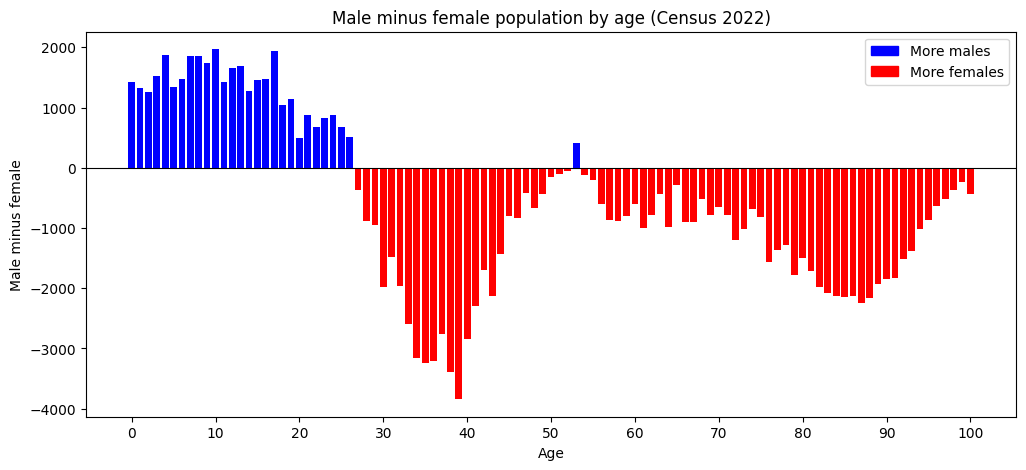

In [10]:
# Bar chart of the difference by age
fig, ax = plt.subplots(figsize=(12, 5))

# Blue bars: more males, Red bars: more females
colours = ["blue" if d >= 0 else "red" for d in df_anal["Difference"]]
ax.bar(df_anal.index, df_anal["Difference"], color=colours)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Male minus female population by age (Census 2022)")
ax.set_xlabel("Age")
ax.set_ylabel("Male minus female")
ax.set_xticks(range(0, 101, 10))
ax.legend(handles=[Patch(color="blue", label="More males"),
                   Patch(color="red", label="More females")])
plt.show()

**Findings:** The weighted mean age is 37.74 for males and 38.94 for females, so females are about 1.20 years older on average. Males outnumber females from age 0 to about 26, by roughly 2,000 people at a single age. From about age 27, females outnumber males at almost every age, with the largest gap around age 39 (nearly 4,000 more women than men) and a second large gap in the late 80s. The ony exception is age 53, where males are slightly ahead. This pattern is probably because more boys than girls are born, while women liver longer and so make up more of the older population.

## Part 2: Age group a chosen age

In [11]:
# Chosen age
age = 35

# Age group: 5 years below to 5 years above the chosen age (30 to 40)
low = age - 5
high = age + 5

# Rows for ages low to high (both ends included)
group = df_anal.loc[low:high]

# Total male and female in the age group
male_total = group["Male"].sum()
female_total = group["Female"].sum()

print(f"Age group: {low} to {high}")
print(f"Males: {male_total:,}")
print(f"Females: {female_total:,}")
print(f"Difference (male - female): {male_total - female_total:,}")


Age group: 30 to 40
Males: 384,030
Females: 414,506
Difference (male - female): -30,476


**Findings:** In the 30 to 40 age group there are 384,030 males and 414,506 females, so there are 30,476 more females than males. I read "within 5 years of that age" as 5 years either side of 35, giving ages 30 to 40.

## Part 3: Region with the biggest difference in the age group

In [12]:
# Keep only the rows inside the age group
df_age = df[(df["Single Year of Age"] >= low) & (df["Single Year of Age"] <= high)]

# Male and female totals for each county
df_county = pd.pivot_table(df_age, 'VALUE', "Administrative Counties", "Sex", aggfunc="sum")

# Male minus female for each county
df_county["Difference"] = df_county["Male"] - df_county["Female"]

# Size of the difference, ignoring the sign
df_county["Abs difference"] = df_county["Difference"].abs()

# Five counties with the biggest difference
df_county.sort_values("Abs difference", ascending=False).head(5)

Sex,Female,Male,Difference,Abs difference
Administrative Counties,,,,
Fingal County Council,29092,26150,-2942,2942
Cork County Council,26545,23706,-2839,2839
South Dublin County Council,26361,23637,-2724,2724
Kildare County Council,20602,18671,-1931,1931
Meath County Council,17715,15981,-1734,1734


In [13]:
# County with the biggest difference
biggest = df_county["Abs difference"].idxmax()
print(f"Biggest difference in ages {low} to {high}: {biggest}")
print(f"Male minus female: {df_county.loc[biggest, 'Difference']:,}")

Biggest difference in ages 30 to 40: Fingal County Council
Male minus female: -2,942


**Findings:** Fingal has the biggest difference in the 30 to 40 age group, with 2,942 more females than males, followed by Cork County and South Dublin. I used the absolute difference so the result does not depend on which sex is larger. These are large counties, so part of the gap is down to their size.

# END